In [1]:
%load_ext autoreload
%autoreload 2
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = 'all'

import sys
import numpy as np
# import matplotlib.pyplot as plt

code_path = "../src" # linux
sys.path.append(code_path)
sys.path.append(code_path+"/src")

import utilities as util
from anony_interface import ANInference
from xai_vad_zsam_interface import GRAD4VAD_XAI_PPA

%matplotlib inline

## GDSN AN System (Ours): Grounding DINO + SAM2 (large) + Negative Seg

In [2]:
ANObj = ANInference(anony_method="mask", 
                    detector_name="body__grounddino_sam",
                    detector_version="grounding-dino-tiny__sam2.1-hiera-large",
                    detector_imgsz=None,
                    detection_thr=0.35,
                    detection_classes=[0] # person
                    )

init_anonymizer...
{'detector_name': 'body__grounddino_sam', 'kwargs_anony_method': {'color_format': 'bgr', 'alpha': 1.0, 'color': '#000000', 'preprocessors_list': [], 'postprocessors_list': []}, 'kwargs_detector_method': {'seg_type': 'instant', 'classes': [0], 'detector_version': 'grounding-dino-tiny__sam2.1-hiera-large', 'detection_thr': 0.35, 'imgsz': None, 'sahi_kwargs': None, 'device': 'cuda'}, 'target_resolution': None, 'isreset_cache': True}
loading object detector...
{'anony_type': 'body', 'seg_type': 'instant', 'classes': [0], 'detector_version': 'grounding-dino-tiny__sam2.1-hiera-large', 'detection_thr': 0.35, 'imgsz': None, 'sahi_kwargs': None, 'device': 'cuda'}
model:  grounding-dino-tiny__sam2.1-hiera-large
loading grounding-dino-tiny, and sam2.1-hiera-large


Loading weights: 100%|██████████| 978/978 [00:01<00:00, 528.67it/s]
[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.
Loading weights: 100%|██████████| 741/741 [00:01<00:00, 426.16it/s] 

{'method': <function ConventionalImageAnonymizer.silhoutte at 0x7f7a700ed4e0>, 'kwargs': {'color_format': 'bgr', 'alpha': 1.0, 'color': '#000000', 'preprocessors_list': [], 'postprocessors_list': []}}


## Load XAI ZSAM System

In [ ]:
xai_clip_modelname = ["ViT-B/16", "ViT-B/32", "ViT-L/14", "ViT-L/14@336px"][2]
xai_anml_cat_list = None
ADXAIMAP_PPA_Obj = GRAD4VAD_XAI_PPA(xai_clip_modelname=xai_clip_modelname,
                                    xai_anml_cat_list=xai_anml_cat_list,
                                    concept_json_filepath=r"/home/mulugetawa/AI4CITIZENS/PACA/src/model/clip/llmv2_custom-concept.json",
                                    prompt_feature_np_filepath=rf"/home/mulugetawa/AI4CITIZENS/PACA/src/model/clip/anml_class_prompt_clip_features_norm_llmv2_custom_{xai_clip_modelname.replace('-','').replace('/','')}.npy",
                                    device="cuda"
                                    )

CLIP4VAD_XAI init...
Model parameters: 427616513
Input resolution: 224
Kernel size: (14, 14)
Context length: 77
Vocab size: 49408
Pooling method: max
CLIP image preprocess function:  Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    <function _convert_image_to_rgb at 0x7f7a6ff3be20>
    ToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)
Loading Pre-computed Normalized CLIP text embedding....
CLIP Prompt Anomaly Categories: ['violence', 'burglary', 'arson', 'assault', 'explosion', 'gun_holding', 'gun_shooting', 'knife_holding', 'knife_stabbing', 'riot', 'crowd_density', 'person falling', 'car_accident', 'vandalism', 'normal_car_driving', 'children_playing', 'normal_activity']
anml_class_prompt_clip_features_norm: torch.Size([768, 17])
MAP anml_text_prompt_embedding: torch.Size([768, 17])
Processing GRAD4VAD_XAI.__init__: 
GRAD4VAD_XAI.__init__ is done!


### ZSAM Inference: cctv_weapon_dataset

#### Load test image

In [4]:
xai_cat_name = "gun_shooting"
image_filepath_list = [
                    r"/home/mulugetawa/AI4CITIZENS/XAVAD/data/Simuletic/Scene6_4.png", 
                    r"/home/mulugetawa/AI4CITIZENS/XAVAD/data/Simuletic/Scene5_7.png", 
                       r"/home/mulugetawa/AI4CITIZENS/XAVAD/data/Simuletic/Scene5_4.png", 
                       r"/home/mulugetawa/AI4CITIZENS/XAVAD/data/Simuletic/Scene3_19.png",
                       ]
image_arr_list = []
for image_filepath in util.tqdm(image_filepath_list):
    image_arr_rgb= np.asarray(util.PIL.Image.open(image_filepath).convert("RGB")) # rgb
    # image_arr_rgb.shape
    image_arr_list.append(image_arr_rgb)

# cctv_weapon_dataset
image_arr_list[0].shape

100%|██████████| 4/4 [00:00<00:00, 28.85it/s]


(1358, 924, 3)

#### AN Inference

In [5]:
success, image_arr_anonymized_list = ANObj.inference(list(map(lambda x: util.cv2.cvtColor(x, util.cv2.COLOR_RGB2BGR),  image_arr_list)))
image_arr_anonymized_list = list(map(lambda x: util.cv2.cvtColor(x, util.cv2.COLOR_RGB2BGR),  image_arr_anonymized_list))
# if success:
#     util.plot_image_grid(image_arr_anonymized_list, 1, len(image_arr_anonymized_list), return_fig=True, border=1, border_color="white", color_format="RGB")

ANInference.inference: 
Processing ANInference.inference: 
ANInference.inference is done!
process time: 8.6409 seconds.


#### ZSAM Inference

##### Using Grad-ECLIP

In [6]:
autofocus_method = "gradmap_only_xai"
zsam_func = lambda x: ADXAIMAP_PPA_Obj.predict(x, 
                                                autofocus_method=autofocus_method,        
                                                xai_cat_name=xai_cat_name, 
                                                bbox_conf=0.50, ismultibox=False, 
                                                grad_mode="grad_eclip", 
                                                map_score_thr_dict={"map_score_min": 0.0, "map_score_max": None, "map_norm_score_min": 0.0}, 
                                                patch_size=448, step_size=336, 
                                                image_resize_wh=None, 
                                                isplot=True
                                            )
result_maps_list = []
for image_arr_rgb, image_arr_rgb_anonymized in zip(image_arr_list, image_arr_anonymized_list):
    
    boxes_xyxy, fig_pil = zsam_func(image_arr_rgb)
    # fig_pil
    result_maps_list.append(fig_pil)
    boxes_xyxy, fig_pil = zsam_func(image_arr_rgb_anonymized)
    # fig_pil
    result_maps_list.append(fig_pil)

GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 924, 3)
xai_cat_name: gun_shooting, xai_class_idx: 6
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.82963 seconds.
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 924, 3)
xai_cat_name: gun_shooting, xai_class_idx: 6
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.49741 seconds.
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 924, 3)
xai_cat_name: gun_shooting, xai_class_idx: 6
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.40699 seconds.
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 924, 3)
xai_cat_name: gun_shooting, xai_class_idx: 6
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.42956 seconds.
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358

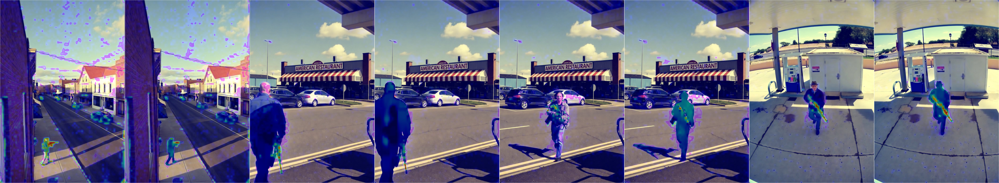

In [7]:
util.plot_image_grid(result_maps_list, 1, len(result_maps_list), return_fig=True, border=1, border_color="white", color_format="RGB")

##### Using Grad-ECLIP + Norm (Ours)

In [8]:
autofocus_method = "gradmap_only_xai"
zsam_func = lambda x:  ADXAIMAP_PPA_Obj.predict(x, 
                                                autofocus_method=autofocus_method,        
                                                xai_cat_name=xai_cat_name, 
                                                bbox_conf=0.50, ismultibox=False, 
                                                grad_mode="grad_eclip", 
                                                map_score_thr_dict={"map_score_min": 0.05, "map_score_max": 0.50, "map_norm_score_min": 0.30}, # needs tuning
                                                patch_size=448, step_size=336, 
                                                image_resize_wh=None, 
                                                isplot=True
                                            )
result_maps_list = []
for image_arr_rgb, image_arr_rgb_anonymized in zip(image_arr_list, image_arr_anonymized_list):
    
    boxes_xyxy, fig_pil = zsam_func(image_arr_rgb)
    # fig_pil
    result_maps_list.append(fig_pil)
    boxes_xyxy, fig_pil = zsam_func(image_arr_rgb_anonymized)
    # fig_pil
    result_maps_list.append(fig_pil)

GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 924, 3)
xai_cat_name: gun_shooting, xai_class_idx: 6
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.50598 seconds.
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 924, 3)
xai_cat_name: gun_shooting, xai_class_idx: 6
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.43749 seconds.
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 924, 3)
xai_cat_name: gun_shooting, xai_class_idx: 6
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.45552 seconds.
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 924, 3)
xai_cat_name: gun_shooting, xai_class_idx: 6
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.42859 seconds.
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358

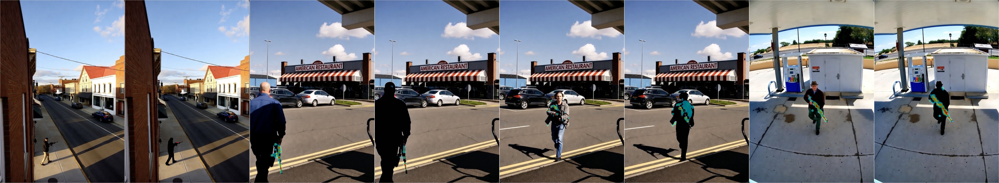

In [9]:
util.plot_image_grid(result_maps_list, 1, len(result_maps_list), return_fig=True, border=1, border_color="white", color_format="RGB")

##### Using Grid Patching + Grad-ECLIP + Norm (Ours)

In [10]:
autofocus_method = "ppa_patch_gradmap_xai"
zsam_func = lambda x:  ADXAIMAP_PPA_Obj.predict(x, 
                                                autofocus_method=autofocus_method,        
                                                xai_cat_name=xai_cat_name, 
                                                bbox_conf=0.50, ismultibox=False, 
                                                grad_mode="grad_eclip", 
                                                map_score_thr_dict={"map_score_min": 0.05, "map_score_max": 0.50, "map_norm_score_min": 0.30}, 
                                                patch_size=448, step_size=336, 
                                                image_resize_wh=None, 
                                                isplot=True
                                            )
result_maps_list = []
for image_arr_rgb, image_arr_rgb_anonymized in zip(image_arr_list, image_arr_anonymized_list):
    
    boxes_xyxy, fig_pil = zsam_func(image_arr_rgb)
    # fig_pil
    result_maps_list.append(fig_pil)
    boxes_xyxy, fig_pil = zsam_func(image_arr_rgb_anonymized)
    # fig_pil
    result_maps_list.append(fig_pil)

GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 924, 3)
xai_cat_name: gun_shooting, xai_class_idx: 6
Running patch sliding window accuracy up...
imsize: (924, 1358), resize_wh: None
image_arr: (1358, 924, 3)
patch_size: 448
patch extraction: input: (1358, 924, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 12
GRAD4VAD_XAI_PPA.predict is done!
process time: 1.5315 seconds.
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 924, 3)
xai_cat_name: gun_shooting, xai_class_idx: 6
Running patch sliding window accuracy up...
imsize: (924, 1358), resize_wh: None
image_arr: (1358, 924, 3)
patch_size: 448
patch extraction: input: (1358, 924, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 12
GRAD4VAD_XAI_PPA.predict is done!
process time: 1.1717 seconds.
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (13

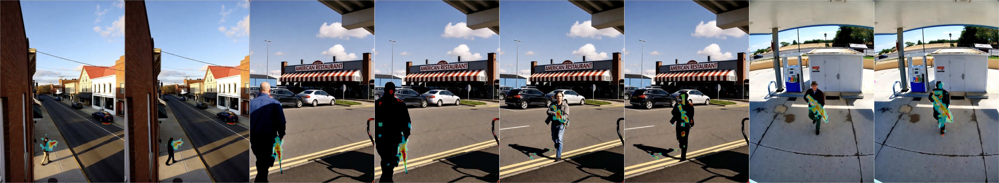

In [11]:
util.plot_image_grid(result_maps_list, 1, len(result_maps_list), return_fig=True, border=1, border_color="white", color_format="RGB")

##### Using Grid Patching (PPA) + Grad-ECLIP + Norm (Ours)

In [12]:
autofocus_method = "ppa_patch_clipcat_gradmap_xai"
zsam_func = lambda x:  ADXAIMAP_PPA_Obj.predict(x,  
                                                autofocus_method=autofocus_method,        
                                                xai_cat_name=xai_cat_name, 
                                                bbox_conf=0.50, ismultibox=False, 
                                                grad_mode="grad_eclip", 
                                                map_score_thr_dict={"map_score_min": 0.05, "map_score_max": 0.50, "map_norm_score_min": 0.30}, 
                                                patch_size=448, step_size=336, 
                                                image_resize_wh=None, 
                                                isplot=True
                                            )
result_maps_list = []
for image_arr_rgb, image_arr_rgb_anonymized in zip(image_arr_list, image_arr_anonymized_list):
    
    boxes_xyxy, fig_pil = zsam_func(image_arr_rgb)
    # fig_pil
    result_maps_list.append(fig_pil)
    boxes_xyxy, fig_pil = zsam_func(image_arr_rgb_anonymized)
    # fig_pil
    result_maps_list.append(fig_pil)

GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 924, 3)
xai_cat_name: gun_shooting, xai_class_idx: 6
Running auto-focus ppa_patch_clipcat_gradmap_xai...
patch extraction: input: (1358, 924, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 12
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 12, device: cuda, video_chunck_freq: 12, pooling_method: max
video frames preprocessing...


100%|██████████| 12/12 [00:00<00:00, 49.55it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 52.46it/s]


Getting class names from labels, video_chunck_freq: 12
CLIP4VAD_XAI.inference is done!
process time: 0.34938 seconds.
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.45135 seconds.
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 924, 3)
xai_cat_name: gun_shooting, xai_class_idx: 6
Running auto-focus ppa_patch_clipcat_gradmap_xai...
patch extraction: input: (1358, 924, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 12
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 12, device: cuda, video_chunck_freq: 12, pooling_method: max
video frames preprocessing...


...

100%|██████████| 12/12 [00:00<00:00, 297.23it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 45.96it/s]

Getting class names from labels, video_chunck_freq: 12
CLIP4VAD_XAI.inference is done!
process time: 0.16853 seconds.


GRAD4VAD_XAI_PPA.predict is done!
process time: 0.27129 seconds.


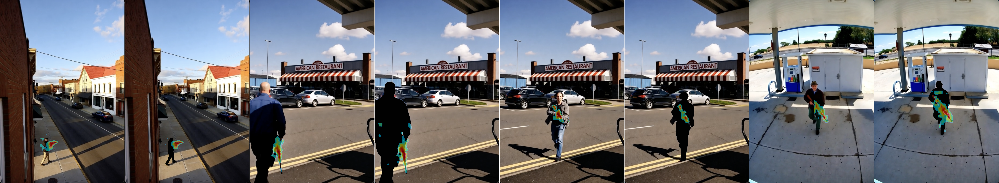

In [13]:
util.plot_image_grid(result_maps_list, 1, len(result_maps_list), return_fig=True, border=1, border_color="white", color_format="RGB")

### ZSAM Inference: cctv_knife_dataset

#### Load test image

In [24]:
xai_cat_name = "knife_holding"
image_filepath_list = [
                       r"/home/mulugetawa/AI4CITIZENS/XAVAD/data/Simuletic/Knife_scenario_98.png",
                       r"/home/mulugetawa/AI4CITIZENS/XAVAD/data/Simuletic/Knife_scenario_31.png",
                       r"/home/mulugetawa/AI4CITIZENS/XAVAD/data/Simuletic/Knife_scenario_53.png",
                       r"/home/mulugetawa/AI4CITIZENS/XAVAD/data/Simuletic/Knife_scenario_78.png",
                       ]
image_arr_list = []
for image_filepath in util.tqdm(image_filepath_list):
    image_arr_rgb = np.asarray(util.PIL.Image.open(image_filepath).convert("RGB")) # rgb
    # image_arr_rgb.shape
    image_arr_list.append(image_arr_rgb)

# cctv_knife_dataset
image_arr_list[-1].shape

100%|██████████| 4/4 [00:00<00:00, 33.43it/s]


(1358, 916, 3)

#### AN Inference

In [25]:
success, image_arr_anonymized_list = ANObj.inference(list(map(lambda x: util.cv2.cvtColor(x, util.cv2.COLOR_RGB2BGR),  image_arr_list)))
image_arr_anonymized_list = list(map(lambda x: util.cv2.cvtColor(x, util.cv2.COLOR_RGB2BGR),  image_arr_anonymized_list))
# if success:
#     util.plot_image_grid(image_arr_anonymized_list, 1, len(image_arr_anonymized_list), return_fig=True, border=1, border_color="white", color_format="RGB")

ANInference.inference: 
Processing ANInference.inference: 


ANInference.inference is done!
process time: 5.7948 seconds.


#### ZSAM Inference

##### Using Grad-ECLIP

In [26]:
autofocus_method = "gradmap_only_xai"
zsam_func = lambda x: ADXAIMAP_PPA_Obj.predict(x, 
                                                autofocus_method=autofocus_method,        
                                                xai_cat_name=xai_cat_name, 
                                                bbox_conf=0.50, ismultibox=False, 
                                                grad_mode="grad_eclip", 
                                                map_score_thr_dict={"map_score_min": 0.0, "map_score_max": None, "map_norm_score_min": 0.0}, 
                                                patch_size=448, step_size=336, 
                                                image_resize_wh=None, 
                                                isplot=True
                                            )
result_maps_list = []
for image_arr_rgb, image_arr_rgb_anonymized in zip(image_arr_list, image_arr_anonymized_list):
    
    boxes_xyxy, fig_pil = zsam_func(image_arr_rgb)
    # fig_pil
    result_maps_list.append(fig_pil)
    boxes_xyxy, fig_pil = zsam_func(image_arr_rgb_anonymized)
    # fig_pil
    result_maps_list.append(fig_pil)

GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 916, 3)
xai_cat_name: knife_holding, xai_class_idx: 7
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.46249 seconds.
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 916, 3)
xai_cat_name: knife_holding, xai_class_idx: 7
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.44734 seconds.
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 916, 3)
xai_cat_name: knife_holding, xai_class_idx: 7
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.39762 seconds.
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 916, 3)
xai_cat_name: knife_holding, xai_class_idx: 7
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.43177 seconds.
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (

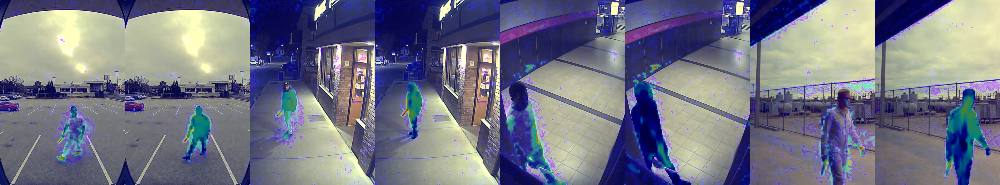

In [27]:
util.plot_image_grid(result_maps_list, 1, len(result_maps_list), return_fig=True, border=1, border_color="white", color_format="RGB")

##### Using Grad-ECLIP + Norm (Ours)

In [28]:
autofocus_method = "gradmap_only_xai"
zsam_func = lambda x:  ADXAIMAP_PPA_Obj.predict(x, 
                                                autofocus_method=autofocus_method,        
                                                xai_cat_name=xai_cat_name, 
                                                bbox_conf=0.50, ismultibox=False, 
                                                grad_mode="grad_eclip", 
                                                map_score_thr_dict={"map_score_min": 0.05, "map_score_max": 0.50, "map_norm_score_min": 0.30}, # needs tuning
                                                patch_size=448, step_size=336, 
                                                image_resize_wh=None, 
                                                isplot=True
                                            )
result_maps_list = []
for image_arr_rgb, image_arr_rgb_anonymized in zip(image_arr_list, image_arr_anonymized_list):
    
    boxes_xyxy, fig_pil = zsam_func(image_arr_rgb)
    # fig_pil
    result_maps_list.append(fig_pil)
    boxes_xyxy, fig_pil = zsam_func(image_arr_rgb_anonymized)
    # fig_pil
    result_maps_list.append(fig_pil)

GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 916, 3)
xai_cat_name: knife_holding, xai_class_idx: 7
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.47251 seconds.
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 916, 3)
xai_cat_name: knife_holding, xai_class_idx: 7
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.42966 seconds.
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 916, 3)
xai_cat_name: knife_holding, xai_class_idx: 7


GRAD4VAD_XAI_PPA.predict is done!
process time: 0.44226 seconds.
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 916, 3)
xai_cat_name: knife_holding, xai_class_idx: 7
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.41337 seconds.
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 916, 3)
xai_cat_name: knife_holding, xai_class_idx: 7
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.44197 seconds.
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 916, 3)
xai_cat_name: knife_holding, xai_class_idx: 7
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.43313 seconds.
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 916, 3)
xai_cat_name: knife_holding, xai_class_idx: 7
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.41086 seconds.
GRAD4VAD_XAI_PPA.predict: 
Processi

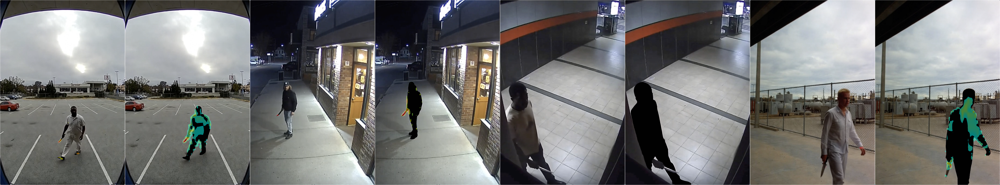

In [29]:
util.plot_image_grid(result_maps_list, 1, len(result_maps_list), return_fig=True, border=1, border_color="white", color_format="RGB")

##### Using Grid Patching + Grad-ECLIP + Norm (Ours)

In [30]:
autofocus_method = "ppa_patch_gradmap_xai"
zsam_func = lambda x:  ADXAIMAP_PPA_Obj.predict(x, 
                                                autofocus_method=autofocus_method,        
                                                xai_cat_name=xai_cat_name, 
                                                bbox_conf=0.50, ismultibox=False, 
                                                grad_mode="grad_eclip", 
                                                map_score_thr_dict={"map_score_min": 0.05, "map_score_max": 0.50, "map_norm_score_min": 0.30}, 
                                                patch_size=448, step_size=336, 
                                                image_resize_wh=None, 
                                                isplot=True
                                            )
result_maps_list = []
for image_arr_rgb, image_arr_rgb_anonymized in zip(image_arr_list, image_arr_anonymized_list):
    
    boxes_xyxy, fig_pil = zsam_func(image_arr_rgb)
    # fig_pil
    result_maps_list.append(fig_pil)
    boxes_xyxy, fig_pil = zsam_func(image_arr_rgb_anonymized)
    # fig_pil
    result_maps_list.append(fig_pil)

GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 916, 3)
xai_cat_name: knife_holding, xai_class_idx: 7
Running patch sliding window accuracy up...
imsize: (916, 1358), resize_wh: None
image_arr: (1358, 916, 3)
patch_size: 448
patch extraction: input: (1358, 916, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 12


GRAD4VAD_XAI_PPA.predict is done!
process time: 1.1208 seconds.
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 916, 3)
xai_cat_name: knife_holding, xai_class_idx: 7
Running patch sliding window accuracy up...
imsize: (916, 1358), resize_wh: None
image_arr: (1358, 916, 3)
patch_size: 448
patch extraction: input: (1358, 916, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 12
GRAD4VAD_XAI_PPA.predict is done!
process time: 1.177 seconds.
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 916, 3)
xai_cat_name: knife_holding, xai_class_idx: 7
Running patch sliding window accuracy up...
imsize: (916, 1358), resize_wh: None
image_arr: (1358, 916, 3)
patch_size: 448
patch extraction: input: (1358, 916, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 12
GRAD4VAD_XAI_PPA.predict is done!
process time: 1.1308 seconds.
GRAD4VAD_XAI_PPA.predict: 
Processing

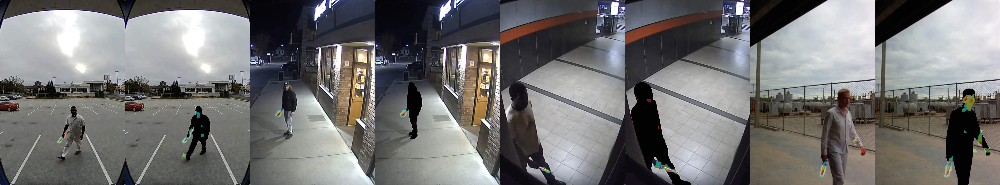

In [31]:
util.plot_image_grid(result_maps_list, 1, len(result_maps_list), return_fig=True, border=1, border_color="white", color_format="RGB")

##### Using Grid Patching (PPA) + Grad-ECLIP + Norm (Ours)

In [32]:
autofocus_method = "ppa_patch_clipcat_gradmap_xai"
zsam_func = lambda x:  ADXAIMAP_PPA_Obj.predict(x,  
                                                autofocus_method=autofocus_method,        
                                                xai_cat_name=xai_cat_name, 
                                                bbox_conf=0.50, ismultibox=False, 
                                                grad_mode="grad_eclip", 
                                                map_score_thr_dict={"map_score_min": 0.05, "map_score_max": 0.50, "map_norm_score_min": 0.30}, 
                                                patch_size=448, step_size=336, 
                                                image_resize_wh=None, 
                                                isplot=True
                                            )
result_maps_list = []
for image_arr_rgb, image_arr_rgb_anonymized in zip(image_arr_list, image_arr_anonymized_list):
    
    boxes_xyxy, fig_pil = zsam_func(image_arr_rgb)
    # fig_pil
    result_maps_list.append(fig_pil)
    boxes_xyxy, fig_pil = zsam_func(image_arr_rgb_anonymized)
    # fig_pil
    result_maps_list.append(fig_pil)

GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 916, 3)
xai_cat_name: knife_holding, xai_class_idx: 7
Running auto-focus ppa_patch_clipcat_gradmap_xai...
patch extraction: input: (1358, 916, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 12
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 12, device: cuda, video_chunck_freq: 12, pooling_method: max
video frames preprocessing...


100%|██████████| 12/12 [00:00<00:00, 50.32it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 59.91it/s]


Getting class names from labels, video_chunck_freq: 12
CLIP4VAD_XAI.inference is done!
process time: 0.34155 seconds.
GRAD4VAD_XAI_PPA.predict is done!
process time: 0.45007 seconds.
GRAD4VAD_XAI_PPA.predict: 
Processing GRAD4VAD_XAI_PPA.predict: 
config: 0.5, iou: 0.5
image_rgb:  (1358, 916, 3)
xai_cat_name: knife_holding, xai_class_idx: 7
Running auto-focus ppa_patch_clipcat_gradmap_xai...
patch extraction: input: (1358, 916, 3), window_shape: (448, 448), step_size: (336, 336), n_pathes: 12
CLIP4VAD_XAI.inference: 
Processing CLIP4VAD_XAI.inference: 
Encoding video frames using CLIP model: ViT-L/14, batch_size: 12, device: cuda, video_chunck_freq: 12, pooling_method: max
video frames preprocessing...


...

100%|██████████| 12/12 [00:00<00:00, 279.37it/s]


CLIP encoding video frames...


100%|██████████| 1/1 [00:00<00:00, 50.42it/s]

Getting class names from labels, video_chunck_freq: 12
CLIP4VAD_XAI.inference is done!
process time: 0.14847 seconds.


GRAD4VAD_XAI_PPA.predict is done!
process time: 0.26158 seconds.


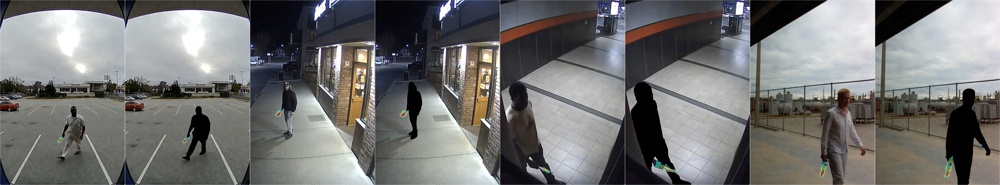

In [33]:
util.plot_image_grid(result_maps_list, 1, len(result_maps_list), return_fig=True, border=1, border_color="white", color_format="RGB")